# 🔍 Module 3: Prototype Search Engine
**Architecture:** $\alpha$-FPS (Adaptive Farthest Point Sampling) + Pinecone + MongoDB
**Pipeline:** # 1. Load `identity_buffer.pkl` from Module 2.
2. Run $\alpha$-FPS to extract K=3 optimal Prototypes per person and upsert to Pinecone.
3. Accept a Query Image -> Embed -> Search Pinecone -> Fetch Trajectory & Image from MongoDB.

### 🛠️ Cell 1: Environment Setup & Credentials

In [38]:
%%capture
!pip install ultralytics boxmot opencv-python scipy torch torchvision
!pip install pinecone pymongo matplotlib

import os
import cv2
import torch
import pickle
import numpy as np
import urllib.request
import matplotlib.pyplot as plt
import torch.nn.functional as F
from pathlib import Path
from pinecone import Pinecone
from pymongo import MongoClient
from kaggle_secrets import UserSecretsClient
from tqdm.auto import tqdm
import time
import shutil

# ══════════════════════════════════════════════════════════════
# 1. CREDENTIALS
# ══════════════════════════════════════════════════════════════
try:
    secrets = UserSecretsClient()
    PINECONE_API_KEY = secrets.get_secret("PINECONE_API_KEY")
    MONGO_URI        = secrets.get_secret("MONGO_URI")
except:
    PINECONE_API_KEY = "YOUR_PINECONE_KEY"
    MONGO_URI        = "YOUR_MONGO_URI"

PINECONE_INDEX_NAME = "supermarket-reid"
BUFFER_PATH = Path('/kaggle/input/datasets/abderrahimzineddine/module2-embeddings/identity_buffer(1).pkl')

print("Dependencies and Credentials Ready.")

### 🧠 Cell 2: Connect to Cloud & Initialize ReID Model

In [39]:
import boxmot
import pkgutil
import inspect

# 1. Initialize Cloud Databases
print("Connecting to Pinecone...")
pc = Pinecone(api_key=PINECONE_API_KEY)
index = pc.Index(PINECONE_INDEX_NAME)

print("Connecting to MongoDB Atlas...")
mongo_client = MongoClient(MONGO_URI)
db = mongo_client["supermarket_db"]
persons_col = db["persons"]

# 2. Initialize the exact same CLIP-ReID model used in Module 2
REID_DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'

ReID = None
for importer, modname, ispkg in pkgutil.walk_packages(boxmot.__path__, boxmot.__name__ + '.'):
    try:
        mod = __import__(modname, fromlist="dummy")
        for name, obj in inspect.getmembers(mod):
            if inspect.isclass(obj) and name in ['ReID', 'ReIDDetectMultiBackend']:
                ReID = obj; break
    except Exception: continue
    if ReID is not None: break

print("Loading CLIP-Market1501...")
reid_model = ReID(weights='clip_market1501.pt', device=REID_DEVICE, half=False)

def embed_image(img_bgr):
    """Takes a raw BGR crop and returns a 512-d normalized tensor."""
    with torch.no_grad():
        emb = reid_model([img_bgr])
        if isinstance(emb, np.ndarray): emb = torch.tensor(emb)
        return F.normalize(emb, p=2, dim=1).to(REID_DEVICE)

Connecting to Pinecone...
Connecting to MongoDB Atlas...


INFO     | BoxMOT v17.0.0 🚀 Python-3.12.12 torch-2.10.0+cu128
CUDA:0 (Tesla T4, 14913MiB)
INFO     | /usr/local/lib/python3.12/dist-packages/models/clip_market1501.pt
INFO     | [PID 57] Found existing ReID weights at /usr/local/lib/python3.12/dist-packages/models/clip_market1501.pt; skipping download.


Loading CLIP-Market1501...
Resized position embedding: %s to %s torch.Size([197, 768]) torch.Size([129, 768])
Position embedding resize to height:16 width: 8


SUCCESS  | Loaded pretrained weights from /usr/local/lib/python3.12/dist-packages/models/clip_market1501.pt


### 📐 Cell 3: The $\alpha$-FPS Math & Index Builder
This calculates the optimal 3 Prototypes per person based on Quality AND Geometric Diversity.

In [40]:
def alpha_fps(embeddings, quality_scores, K=3, alpha=0.5):
    """
    Selects K prototypes maximizing both quality (confidence) and diversity (distance).
    """
    N = embeddings.shape[0]
    if N <= K: 
        return list(range(N))
        
    selected = []
    
    # 1st Prototype: Absolute highest quality crop
    first = torch.argmax(quality_scores).item()
    selected.append(first)
    
    # Track minimum distance from any point to the selected prototype set
    distances = 1.0 - torch.mm(embeddings, embeddings[first].unsqueeze(1)).squeeze()
    
    for _ in range(1, K):
        # Combined score: Quality vs Distance to existing prototypes
        combined_score = (alpha * quality_scores) + ((1.0 - alpha) * distances)
        combined_score[selected] = -1.0 # Disqualify already selected
        
        nxt = torch.argmax(combined_score).item()
        selected.append(nxt)
        
        # Update distances (each point's distance is the MINIMUM distance to ANY prototype)
        new_dist = 1.0 - torch.mm(embeddings, embeddings[nxt].unsqueeze(1)).squeeze()
        distances = torch.min(distances, new_dist)
        
    return selected

def build_prototype_index(K=3, alpha=0.5):
    """Runs once at the end of the day. Reads RAM buffer and populates Pinecone."""
    if not BUFFER_PATH.exists():
        print("❌ Error: identity_buffer.pkl not found! Run Module 2 first.")
        return
        
    print("Clearing Pinecone for fresh prototype insertion...")
    try: index.delete(delete_all=True, namespace="")
    except: pass
    
    print("Loading RAM Buffer...")
    with open(BUFFER_PATH, 'rb') as f:
        saved_data = pickle.load(f)
        
    total_protos = 0
    upsert_batch = []
    
    for gid, data in tqdm(saved_data.items(), desc="Calculating α-FPS Prototypes"):
        embs = torch.tensor(np.array(data["embeddings"])).to(REID_DEVICE)
        
        # Quality = Detection Confidence * Skeleton Visible Ratio
        quality_scores = torch.tensor(data["det_scores"]).to(REID_DEVICE) * torch.tensor(data["ratios"]).to(REID_DEVICE)
        
        # Extract the K best indices
        best_indices = alpha_fps(embs, quality_scores, K=K, alpha=alpha)
        
        for p_idx, idx in enumerate(best_indices):
            vector_list = embs[idx].cpu().numpy().tolist()
            upsert_batch.append({
                "id": f"global_{gid}_proto_{p_idx+1}",
                "values": vector_list,
                "metadata": {"global_id": gid, "prototype_idx": p_idx+1}
            })
            total_protos += 1
            
    # Push to Pinecone
    print(f"Pushing {total_protos} Prototypes to Pinecone...")
    index.upsert(vectors=upsert_batch)
    print("✅ Pinecone Index successfully built!")

### 🕵️ Cell 4: The Intelligent Search Engine

In [41]:
def search_person(query_img_bgr, top_k=3, th_emb=0.75, tau=1.5):
    """
    Embeds the query, searches Pinecone, applies Softmax ambiguity logic,
    and returns full MongoDB tracking data.
    """
    query_emb = embed_image(query_img_bgr)
    vector_list = query_emb.cpu().numpy().tolist()[0]
    
    # We ask for a wide neighborhood so we can check for Softmax ambiguity
    response = index.query(vector=vector_list, top_k=10, include_metadata=True)
    
    if not response.matches or response.matches[0].score < th_emb:
        return {"status": "UNKNOWN", "reason": "Failed absolute distance threshold (No one similar found)."}
        
    # Group results by Global ID (Taking the MAX score per ID, not the muddy average!)
    id_scores = {}
    for match in response.matches:
        gid = match.metadata["global_id"]
        if gid not in id_scores:
            id_scores[gid] = match.score
            
    sorted_ids = sorted(id_scores.items(), key=lambda x: x[1], reverse=True)
    best_gid, best_score = sorted_ids[0]
    
    # Inter-class ambiguity check (Softmax Ratio)
    if len(sorted_ids) > 1:
        max_score, second_score = sorted_ids[0][1], sorted_ids[1][1]
        # Temperature scaling matching Module 2
        probs = F.softmax(torch.tensor([max_score, second_score]) * 15.0, dim=0)
        ratio = probs[0].item() / (probs[1].item() + 1e-9)
        
        if ratio < tau:
            return {
                "status": "AMBIGUOUS", 
                "reason": f"System confused between GID {best_gid} and GID {sorted_ids[1][0]}. Ratio {ratio:.2f} < {tau}",
                "best_guess_gid": best_gid
            }

    # Match confirmed! Fetch data from MongoDB
    person_doc = persons_col.find_one({"global_id": int(best_gid)}, {"_id": 0})
    if not person_doc:
        return {"status": "ERROR", "reason": "Match found in Pinecone, but no metadata exists in MongoDB."}
        
    return {
        "status": "MATCH",
        "global_id": best_gid,
        "score": best_score,
        "mongodb_data": person_doc
    }

### 🎬 Cell 5: Test Execution & Visualization
Provide an image URL (from your MongoDB sightings or Google) and search for them!


🔍 Searching for person from URL...


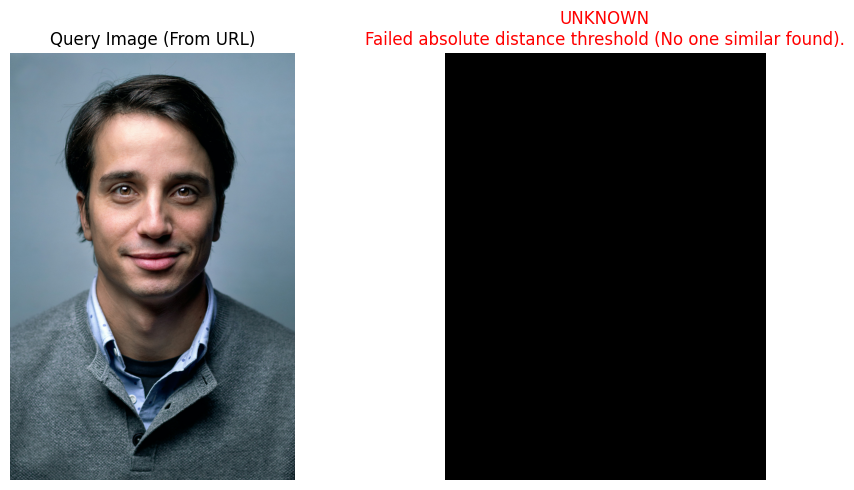

In [42]:
def fetch_image_from_url(url, as_rgb=False):
    """Downloads an image from any URL (MongoDB, ImageKit, or Google)."""
    try:
        # Added User-Agent so Google/Unsplash don't block the request
        req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req) as response:
            arr = np.asarray(bytearray(response.read()), dtype=np.uint8)
            img_bgr = cv2.imdecode(arr, cv2.IMREAD_COLOR)
            if as_rgb:
                return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            return img_bgr
    except Exception as e:
        print(f"Failed to load URL: {e}")
        return np.zeros((256, 192, 3), dtype=np.uint8)

# 1. Build the Index (Uncomment this and run it ONCE to build Pinecone)
# build_prototype_index(K=3, alpha=0.5)

# 2. Paste your Test Image URL here!
# (You can use a 'best_crop_url' from MongoDB or any random image link)
TEST_IMAGE_URL = "https://images.unsplash.com/photo-1500648767791-00dcc994a43e" # <-- PASTE URL HERE

print(f"\n🔍 Searching for person from URL...")
query_img_bgr = fetch_image_from_url(TEST_IMAGE_URL, as_rgb=False)

if query_img_bgr is not None and query_img_bgr.any():
    # 3. SEARCH!
    result = search_person(query_img_bgr)
    
    # 4. Visualize the Result
    plt.figure(figsize=(10, 5))
    
    # Plot Query
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(query_img_bgr, cv2.COLOR_BGR2RGB))
    plt.title("Query Image (From URL)")
    plt.axis("off")
    
    # Plot Database Match
    plt.subplot(1, 2, 2)
    if result["status"] == "MATCH":
        mongo_data = result["mongodb_data"]
        # Grab the best crop URL from their very first sighting
        match_url = mongo_data["sightings"][0]["best_crop_url"]
        match_img_rgb = fetch_image_from_url(match_url, as_rgb=True)
        
        plt.imshow(match_img_rgb)
        title = f"MATCH: Global ID {result['global_id']}\n"
        title += f"Score: {result['score']:.3f}\n"
        title += f"Sightings: {len(mongo_data['sightings'])}"
        plt.title(title, color="green", fontweight="bold")
    else:
        plt.imshow(np.zeros((256, 192, 3), dtype=np.uint8))
        plt.title(f"{result['status']}\n{result['reason']}", color="red")
        
    plt.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("Invalid URL or image could not be loaded.")

### 💣 Cell 6: Detailed Brute Force Stress Test
Iterates through all physical crops in the saved identities folder 
and tests them against the Pinecone Index. Failed/Rejected crops are saved for visual debugging.

In [43]:
# 1. Setup Folders
local_db = Path('/kaggle/input/datasets/abderrahimzineddine/module2-saved-identities')
if not local_db.exists():
    local_db = Path('/kaggle/working/module2_database/saved_identities')

eval_out_dir = Path('/kaggle/working/eval_failures')
failed_dir = eval_out_dir / 'failed_misclassified'
rejected_dir = eval_out_dir / 'rejected_unknown'

if eval_out_dir.exists():
    shutil.rmtree(eval_out_dir)
failed_dir.mkdir(parents=True, exist_ok=True)
rejected_dir.mkdir(parents=True, exist_ok=True)

all_images = list(local_db.rglob("*.jpg"))

if not all_images:
    print(f"❌ No images found in '{local_db}'.")
    print("Please check your folder path or make sure Module 2 ran successfully.")
else:
    print(f"\n🚀 Starting Detailed Brute Force Test on {len(all_images)} physical crops...")
    
    total_tests = 0
    passed_tests = 0
    failed_misclassified = 0 # Engine said "MATCH" but got the wrong ID
    rejected_ambiguous = 0   # Engine said "AMBIGUOUS"
    rejected_unknown = 0     # Engine said "UNKNOWN" (score too low)
    
    search_times = []
    similarity_scores = []
    
    for img_path in tqdm(all_images, desc="Evaluating Gallery"):
        parent_folder = img_path.parent.name
        try:
            true_gid = int(parent_folder.split('_')[-1])
        except:
            continue
            
        query_img_bgr = cv2.imread(str(img_path))
        if query_img_bgr is None:
            continue
            
        total_tests += 1
        
        start_time = time.perf_counter()
        result = search_person(query_img_bgr)
        end_time = time.perf_counter()
        
        search_times.append((end_time - start_time) * 1000)
        
        # --- GRANULAR EVALUATION LOGIC ---
        if result["status"] == "MATCH":
            pred_gid = int(result["global_id"])
            score = result["score"]
            similarity_scores.append(score)
            
            if pred_gid == true_gid:
                passed_tests += 1
            else:
                failed_misclassified += 1
                # Save visual proof
                out_name = f"trueID_{true_gid:03d}_predID_{pred_gid:03d}_score_{score:.2f}.jpg"
                cv2.imwrite(str(failed_dir / out_name), query_img_bgr)
                
        elif result["status"] == "AMBIGUOUS":
            rejected_ambiguous += 1
            # Save visual proof
            out_name = f"trueID_{true_gid:03d}_REJECTED_AMBIGUOUS_guess_{result.get('best_guess_gid', 'none')}.jpg"
            cv2.imwrite(str(rejected_dir / out_name), query_img_bgr)
            
        elif result["status"] == "UNKNOWN":
            rejected_unknown += 1
            # Save visual proof
            out_name = f"trueID_{true_gid:03d}_REJECTED_UNKNOWN.jpg"
            cv2.imwrite(str(rejected_dir / out_name), query_img_bgr)
                
    # Calculate Final Analytics
    accuracy = (passed_tests / total_tests) * 100 if total_tests > 0 else 0
    avg_time = np.mean(search_times) if search_times else 0
    min_time = np.min(search_times) if search_times else 0
    max_time = np.max(search_times) if search_times else 0
    
    avg_score = np.mean(similarity_scores) if similarity_scores else 0
    min_score = np.min(similarity_scores) if similarity_scores else 0
    max_score = np.max(similarity_scores) if similarity_scores else 0
    
    print("\n" + "="*50)
    print(" 📊 DETAILED BRUTE FORCE TEST RESULTS")
    print("="*50)
    print(f"Total Crops Tested : {total_tests}")
    print(f"✅ Passed Tests      : {passed_tests} ({accuracy:.2f}%)")
    print("-" * 50)
    print(f"❌ Failed (Wrong ID) : {failed_misclassified} crops")
    print(f"⚠️ Rejected (Ambig)  : {rejected_ambiguous} crops")
    print(f"⚠️ Rejected (Unknown): {rejected_unknown} crops")
    print("-" * 50)
    print(f"Search Speed (ms)  : Avg: {avg_time:.1f} | Min: {min_time:.1f} | Max: {max_time:.1f}")
    print(f"Similarity Score   : Avg: {avg_score:.3f} | Min: {min_score:.3f} | Max: {max_score:.3f}")
    print("="*50)

    # Zip the failures for download
    if failed_misclassified > 0 or rejected_ambiguous > 0 or rejected_unknown > 0:
        print("\nZipping failure cases for visual debugging...")
        shutil.make_archive('/kaggle/working/evaluation_failures', 'zip', str(eval_out_dir))
        print("✅ Download 'evaluation_failures.zip' to inspect the tricky crops!")


🚀 Starting Detailed Brute Force Test on 887 physical crops...


Evaluating Gallery:   0%|          | 0/887 [00:00<?, ?it/s]


 📊 DETAILED BRUTE FORCE TEST RESULTS
Total Crops Tested : 887
✅ Passed Tests      : 865 (97.52%)
--------------------------------------------------
❌ Failed (Wrong ID) : 7 crops
⚠️ Rejected (Ambig)  : 8 crops
⚠️ Rejected (Unknown): 7 crops
--------------------------------------------------
Search Speed (ms)  : Avg: 133.3 | Min: 28.9 | Max: 1387.7
Similarity Score   : Avg: 0.922 | Min: 0.758 | Max: 1.000

Zipping failure cases for visual debugging...
✅ Download 'evaluation_failures.zip' to inspect the tricky crops!


### 🖼️ Cell 7: Visualizing the Prototypes
Because Pinecone only stores abstract mathematical numbers, we re-run the fast $\alpha$-FPS logic 
over the local buffer to definitively see which 3 images the system chose as its Master Prototypes!


🖼️ Visualizing K=3 Prototypes for 24 Identities...


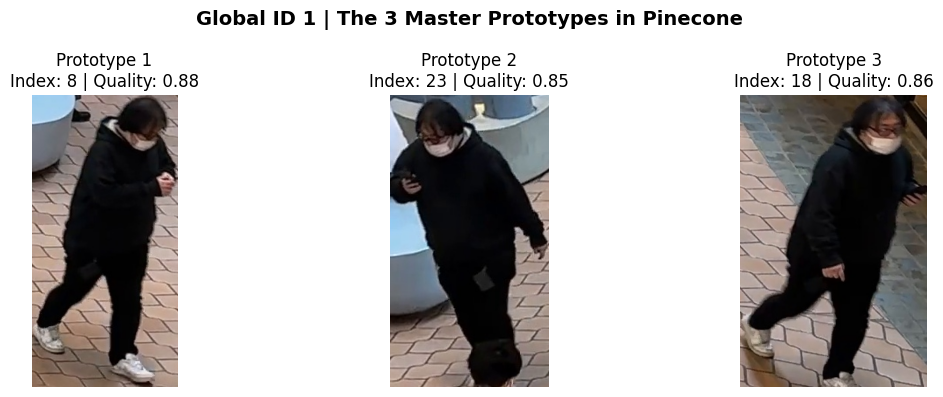

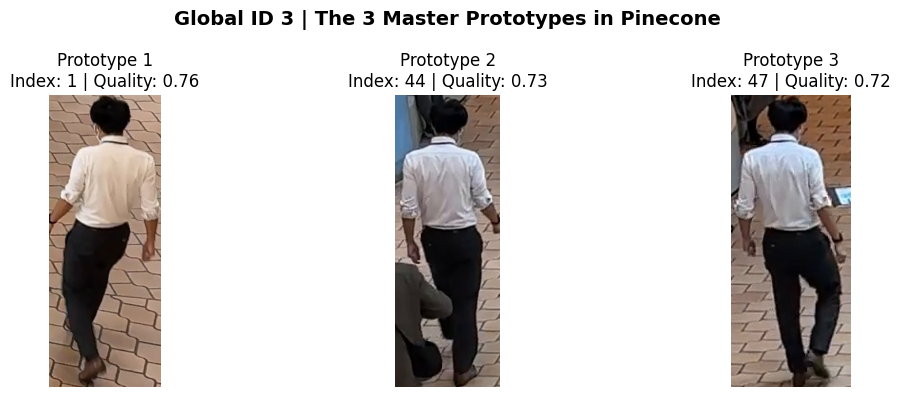

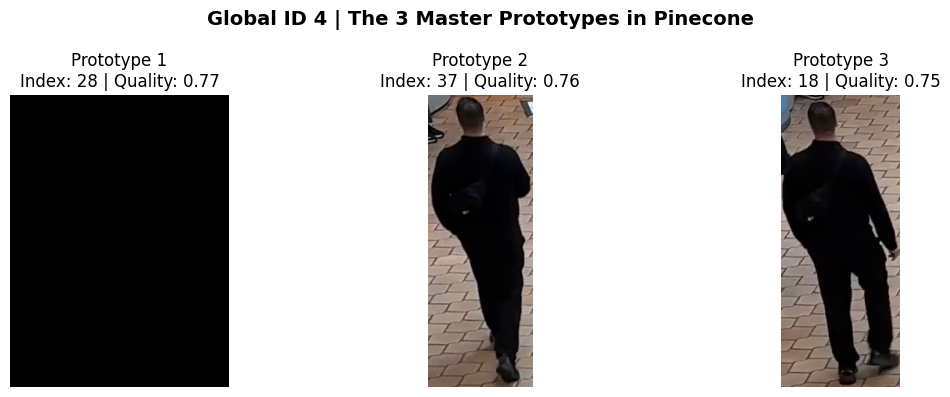

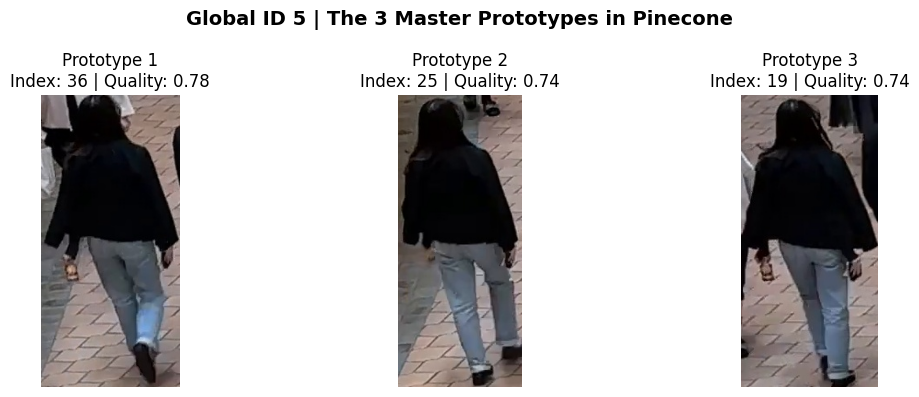

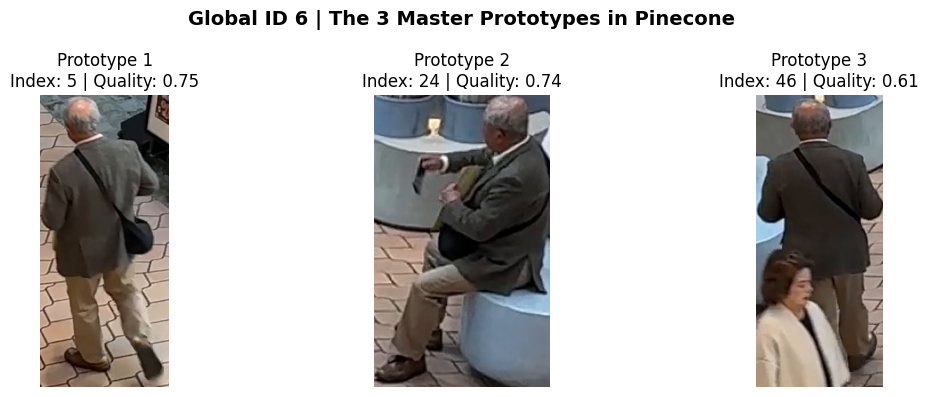

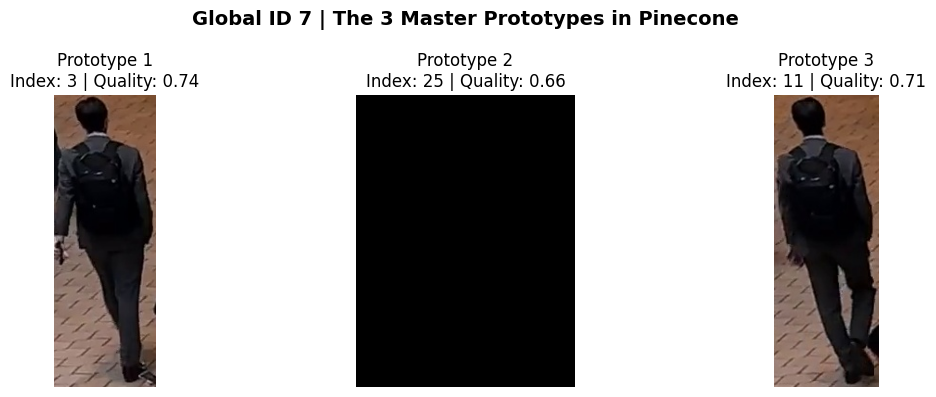

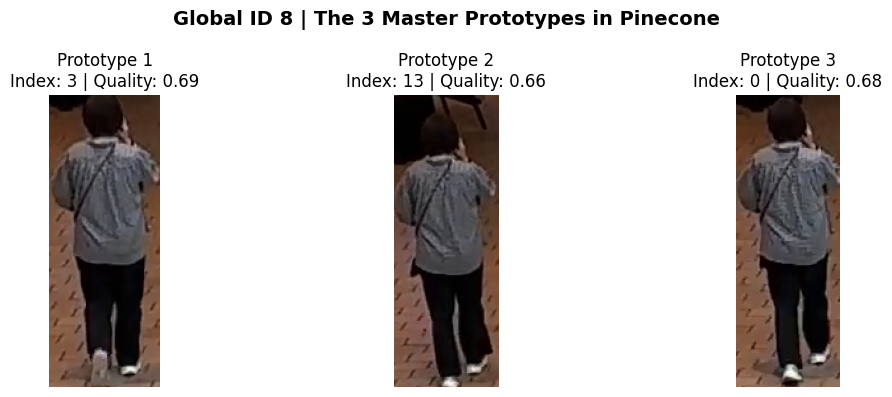

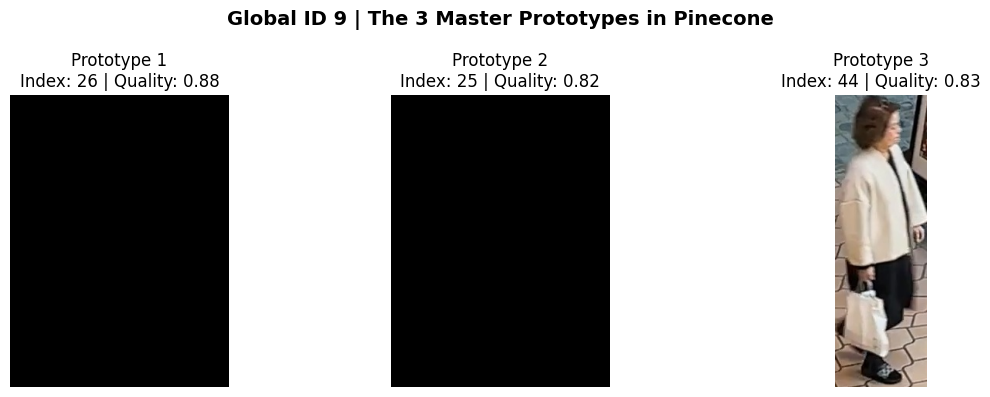

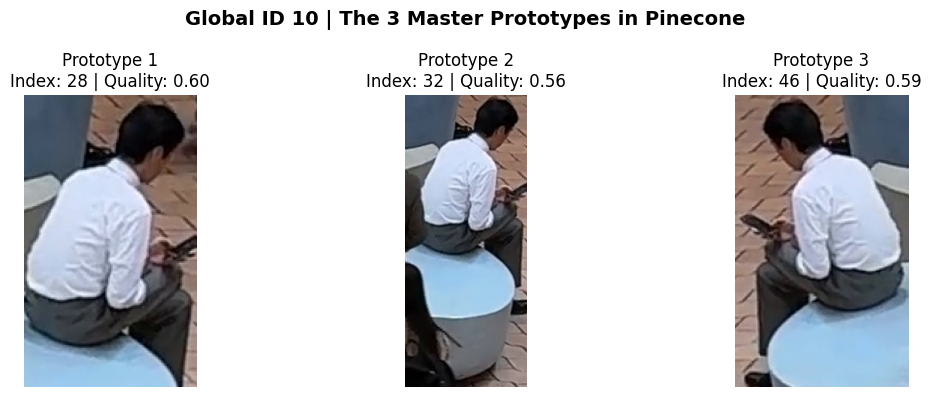

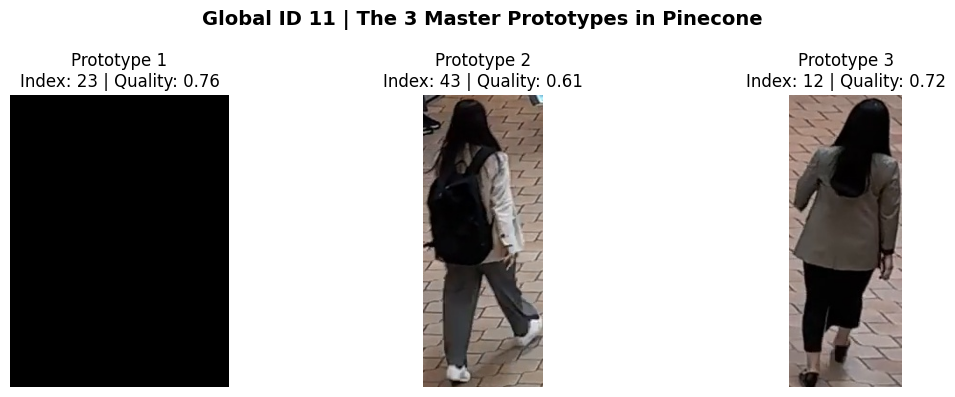

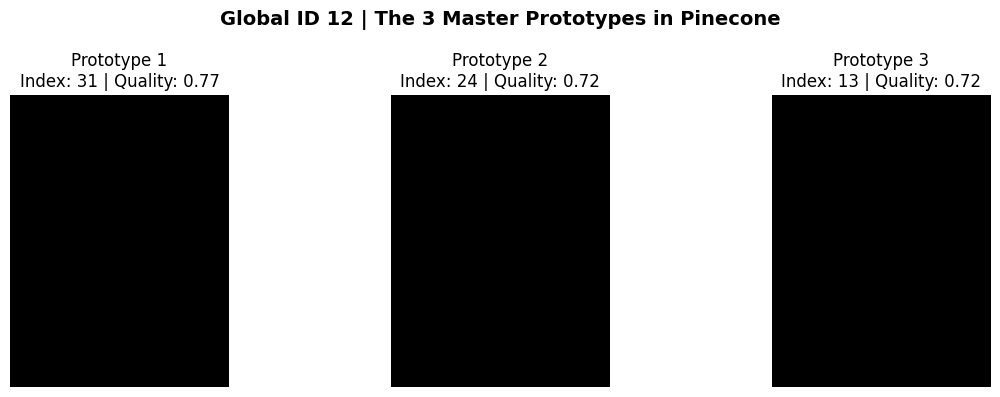

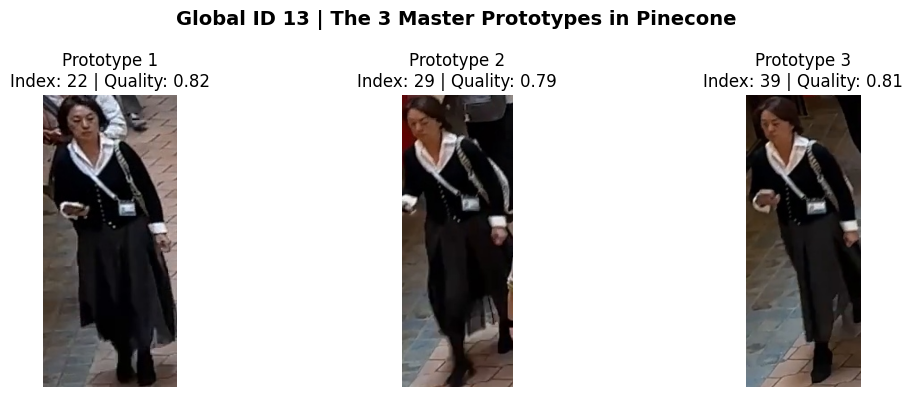

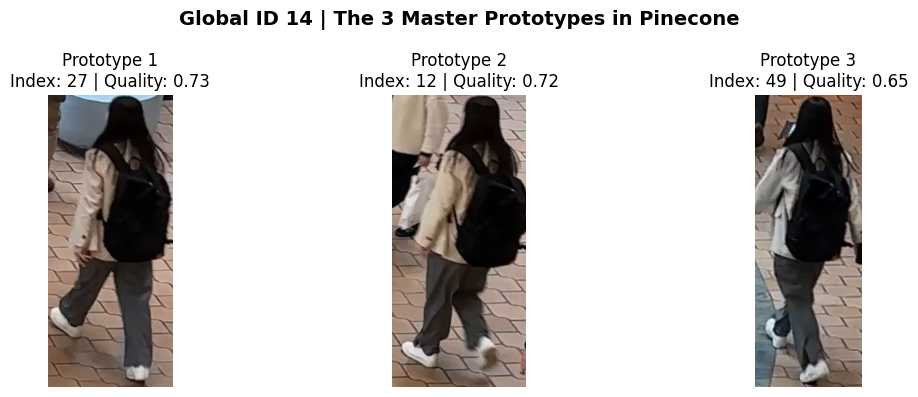

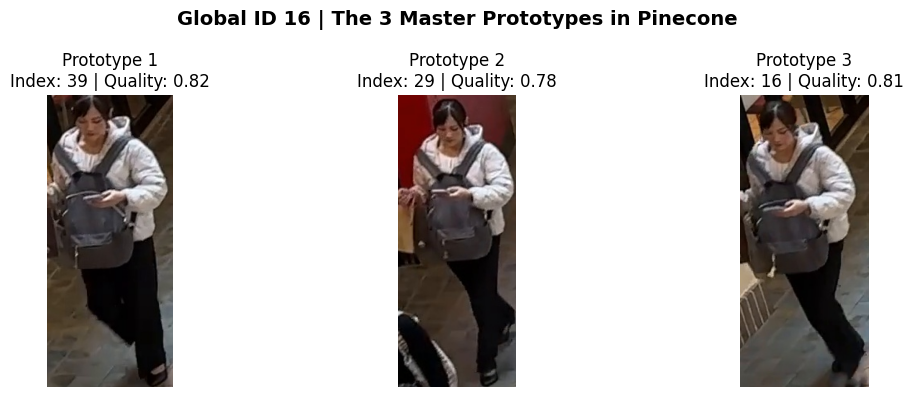

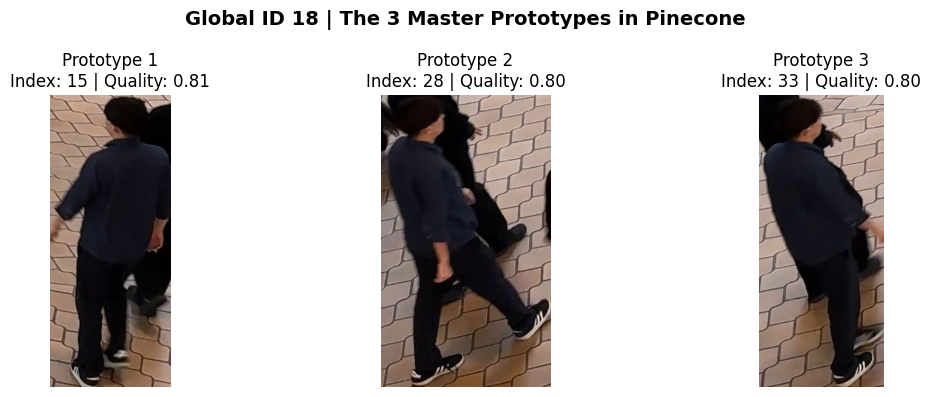

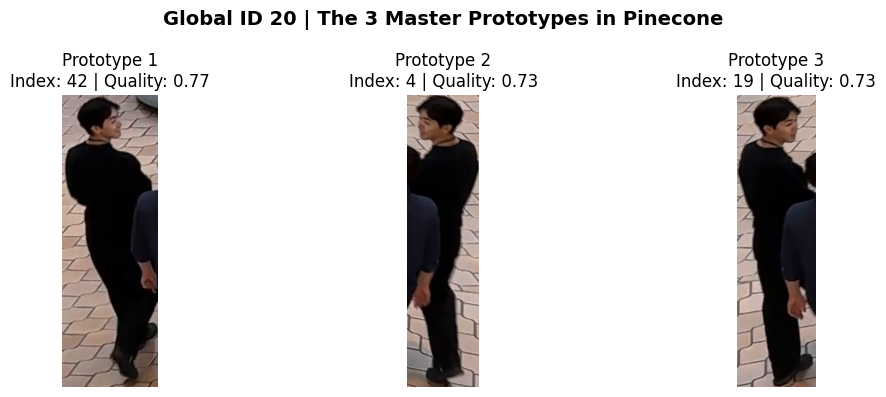

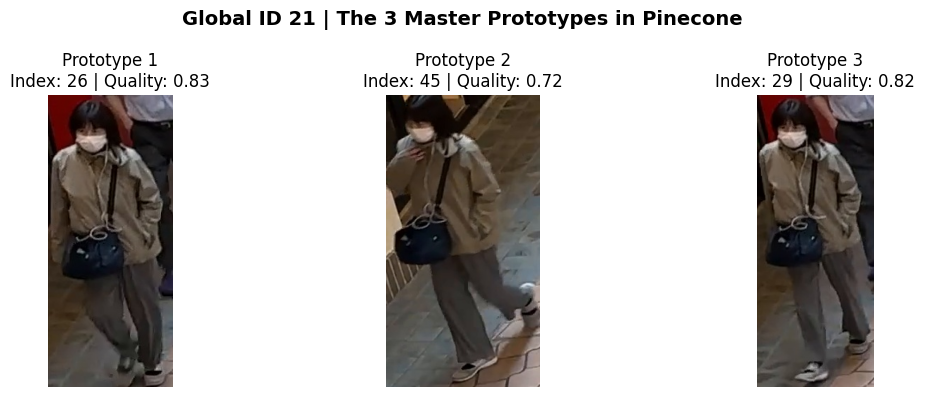

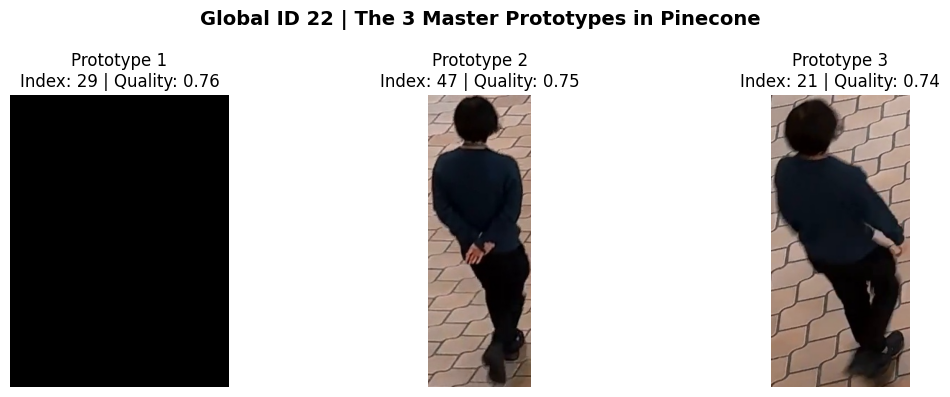

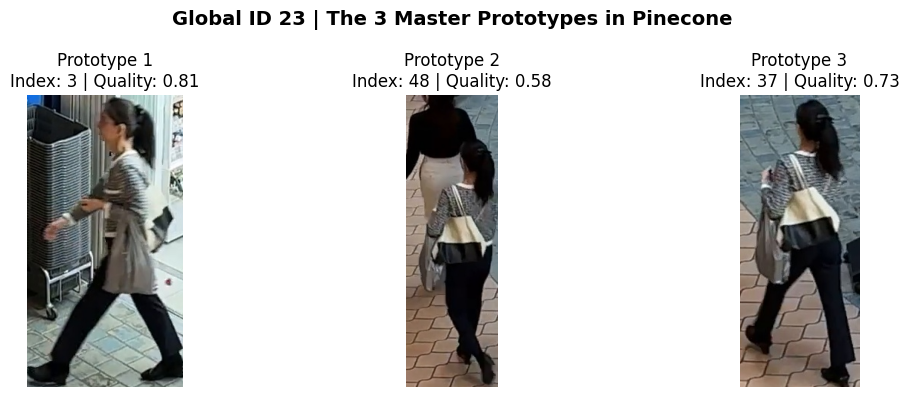

In [45]:
if not BUFFER_PATH.exists():
    print("identity_buffer.pkl not found! Cannot visualize prototypes.")
else:
    # 1. Ensure we know where the images live right now!
    local_db = Path('/kaggle/input/datasets/abderrahimzineddine/module2-saved-identities')
    if not local_db.exists():
        local_db = Path('/kaggle/working/module2_database/saved_identities')
        
    with open(BUFFER_PATH, 'rb') as f:
        saved_data = pickle.load(f)
        
    print(f"\n🖼️ Visualizing K=3 Prototypes for {len(saved_data)} Identities...")
    
    for gid, data in saved_data.items():
        embs = torch.tensor(np.array(data["embeddings"])).to(REID_DEVICE)
        quality_scores = torch.tensor(data["det_scores"]).to(REID_DEVICE) * torch.tensor(data["ratios"]).to(REID_DEVICE)
        
        # 1-millisecond math rerun to find the winning indices
        best_indices = alpha_fps(embs, quality_scores, K=3, alpha=0.5)
        filepaths = data.get("filepaths", [])
        
        if not filepaths:
            continue
            
        fig, axes = plt.subplots(1, len(best_indices), figsize=(12, 4))
        if len(best_indices) == 1:
            axes = [axes]
            
        fig.suptitle(f"Global ID {gid} | The 3 Master Prototypes in Pinecone", fontsize=14, fontweight="bold")
        
        for i, idx in enumerate(best_indices):
            # Extract just the parent folder ("global_id_001") and filename from the old absolute path
            raw_path = Path(filepaths[idx])
            actual_img_path = local_db / raw_path.parent.name / raw_path.name
            
            if actual_img_path.exists():
                img_bgr = cv2.imread(str(actual_img_path))
                img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
                axes[i].imshow(img_rgb)
            else:
                axes[i].imshow(np.zeros((256, 192, 3), dtype=np.uint8))
                
            axes[i].set_title(f"Prototype {i+1}\nIndex: {idx} | Quality: {quality_scores[idx]:.2f}")
            axes[i].axis("off")
            
        plt.tight_layout()
        plt.show()